# Diagnóstico de doenças da cana-de-açúcar por foto da folha com redes neurais
**Estudo experimental de classificação de imagens com redes neurais convolucionais** · PUC Minas · IA aplicada a processos industriais

**Autor:** Claudecir Menezes Francisco

---
### O problema
Doenças como **podridão vermelha, mosaico, ferrugem e amarelinho** reduzem a produtividade (TCH) e o açúcar (ATR) do canavial.
Hoje o diagnóstico em campo é **visual**, feito por técnico, e algumas doenças se confundem no início.
O setor já usa satélite e drone para localizar áreas suspeitas. A classificação de fotos das folhas foi investigada como possível apoio à triagem, sem substituir avaliação agronômica.

### Objetivo e abordagens avaliadas
Foram treinadas e comparadas **três configurações de redes neurais convolucionais** para classificar fotografias de folhas em cinco classes:
1. **CNN do zero** – arquitetura própria, treinada sem pesos pré-treinados
2. **MobileNetV2 congelada** – transfer learning, treinando só as camadas novas
3. **MobileNetV2 com ajuste fino** – liberando as últimas camadas da rede pré-treinada

**Referência para comparar:** os autores da base (Daphal & Koli, *Heliyon*, 2023) obtiveram **84%** com MobileNetV2 e **86,5%** com um ensemble.

### Estrutura do experimento
| Fase | Conteúdo |
|---|---|
| 1 | Ambiente e carregamento das imagens |
| 2 | Exploração |
| 3 | Pré-processamento: duplicatas e divisão treino/validação/teste |
| 4 | Pipeline de imagens e aumento de dados |
| 5 | Modelo 1: CNN do zero |
| 6 | Modelos 2 e 3: transfer learning |
| 7 | Avaliação, comparação e Grad-CAM |
| 8 | Conclusões |

---
## 1. Ambiente e carregamento das imagens

**Ambiente experimental:** Google Colab, com GPU NVIDIA T4 para treinamento dos modelos.


In [ ]:
import tensorflow as tf

print('Versão do TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')     # lista as GPUs que o TensorFlow enxerga
if gpus:
    print('GPU encontrada:', gpus[0].name)
else:
    print('GPU não detectada; execução ocorrerá em CPU')

### 1.2 Bibliotecas utilizadas

- **TensorFlow / Keras:** construção, treinamento e avaliação dos modelos.
- **NumPy / Pandas:** processamento e análise dos dados.
- **Matplotlib:** visualização dos resultados.
- **Pillow (PIL):** leitura e tratamento das imagens.
- **os / glob:** organização e localização dos arquivos.


In [ ]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import keras

# Semente fixa: torna os sorteios (divisão dos dados, pesos iniciais) repetíveis
SEMENTE = 42
random.seed(SEMENTE); np.random.seed(SEMENTE); keras.utils.set_random_seed(SEMENTE)

pd.set_option('display.max_columns', 30)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
print('Bibliotecas carregadas')

Bibliotecas carregadas


### 1.3 Carregamento da base de imagens

A base foi organizada no Google Drive na pasta `TrabalhoRedesNeurais`, em cinco subpastas correspondentes às classes (`Healthy`, `Mosaic`, `RedRot`, `Rust` e `Yellow`). Os arquivos são copiados para `/content/dados` no ambiente Colab para reduzir o tempo de leitura durante o processamento e o treinamento.

**Reprodução:** o caminho da pasta no Google Drive deve ser adaptado ao ambiente de quem executar o notebook.


In [ ]:
import shutil

PASTA_DRIVE = '/content/drive/MyDrive/TrabalhoRedesNeurais'   # pasta do projeto no Drive
PASTA_DADOS = '/content/dados'                                 # cópia local, mais rápida

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:                       # execução fora do ambiente Colab
    PASTA_DRIVE = os.environ.get('PASTA_DRIVE', '.')
    PASTA_DADOS = os.environ.get('PASTA_DADOS', './dados')

# Localiza a pasta da base: é a que contém a subpasta "Healthy"
achados = glob.glob(os.path.join(PASTA_DRIVE, '**', 'Healthy'), recursive=True)
assert achados, f'Pasta da base (com a subpasta Healthy) não encontrada em {PASTA_DRIVE}'
ORIGEM = os.path.dirname(achados[0])
print('Base encontrada em:', ORIGEM)

if not os.path.exists(PASTA_DADOS):                  # cópia local, se ainda não existente
    shutil.copytree(ORIGEM, PASTA_DADOS)
print('Imagens disponíveis em', PASTA_DADOS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base encontrada em: /content/drive/MyDrive/TrabalhoRedesNeurais
Imagens disponíveis em /content/dados


### 1.4 Montar a tabela de imagens
Cada imagem está dentro de uma pasta com o nome da sua classe (ex.: `Rust/foto123.jpg`).
A varredura das pastas gera uma tabela com **caminho do arquivo** e **classe**, com nomes de classes padronizados em português.

In [ ]:
# Tradução dos nomes das pastas (chave sem espaços/underline, em minúsculas)
TRADUCAO = {'healthy': 'Sadia', 'mosaic': 'Mosaico', 'redrot': 'Podridão vermelha',
            'rust': 'Ferrugem', 'yellow': 'Amarelinho'}

EXTENSOES = ('.jpg', '.jpeg', '.png')
registros = []
for raiz, _, arquivos in os.walk(PASTA_DADOS):
    for nome in arquivos:
        if nome.lower().endswith(EXTENSOES):
            pasta = os.path.basename(raiz)                         # nome da pasta = classe
            chave = pasta.lower().replace(' ', '').replace('_', '').replace('disease', '')
            registros.append({'caminho': os.path.join(raiz, nome),
                              'pasta_original': pasta,
                              'classe': TRADUCAO.get(chave, pasta)})

df = pd.DataFrame(registros)
print(f'Total de imagens: {len(df)}')
print('Pastas encontradas e tradução:')
print(df.groupby(['pasta_original', 'classe']).size().to_string())

Total de imagens: 2521
Pastas encontradas e tradução:
pasta_original  classe           
Healthy         Sadia                522
Mosaic          Mosaico              462
RedRot          Podridão vermelha    518
Rust            Ferrugem             514
Yellow          Amarelinho           505


In [ ]:
# Ordem fixa das classes (usada em todos os gráficos e na saída da rede)
CLASSES = ['Sadia', 'Mosaico', 'Podridão vermelha', 'Ferrugem', 'Amarelinho']
assert set(df['classe']) == set(CLASSES), f'Classes inesperadas: {set(df.classe) - set(CLASSES)}'

contagem = df['classe'].value_counts().reindex(CLASSES)
pd.DataFrame({'imagens': contagem, '% do total': (contagem / len(df) * 100).round(1)})

,imagens,% do total
classe,,
Sadia,522,20.7
Mosaico,462,18.3
Podridão vermelha,518,20.5
Ferrugem,514,20.4
Amarelinho,505,20.0


---
## Fase 2 · Exploração das imagens
Foram avaliados a distribuição das classes, as características visuais e os tamanhos das fotografias.

### 2.1 Equilíbrio entre as classes
A distribuição relativamente equilibrada entre as cinco classes favorece a interpretação da acurácia global; métricas por classe também foram consideradas.

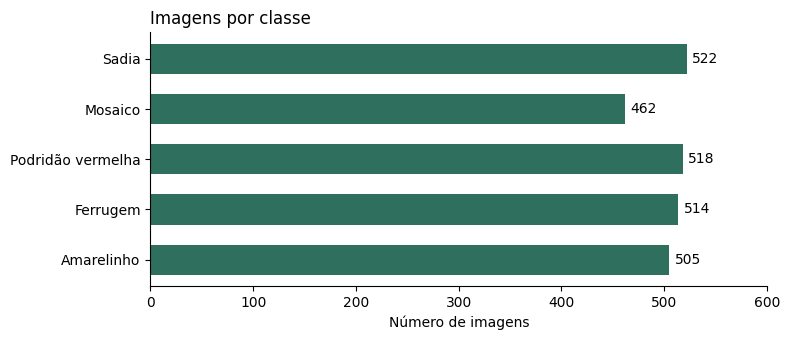

In [ ]:
COR = '#2f6f5e'                                      # verde-escuro, uma só cor: a classe já está no eixo
fig, ax = plt.subplots(figsize=(8, 3.5))
barras = ax.barh(CLASSES[::-1], contagem[CLASSES[::-1]], color=COR, height=0.6)
ax.bar_label(barras, padding=4, fontsize=10)         # número ao lado de cada barra
ax.set_xlabel('Número de imagens')
ax.set_title('Imagens por classe', loc='left')
ax.set_xlim(0, contagem.max() * 1.15)
plt.tight_layout(); plt.show()

### 2.2 Como é cada doença
Foram sorteadas seis imagens por classe para observar variações de **fundo, iluminação e enquadramento**. Esses fatores podem introduzir padrões indesejados e foram considerados na análise qualitativa com Grad-CAM.

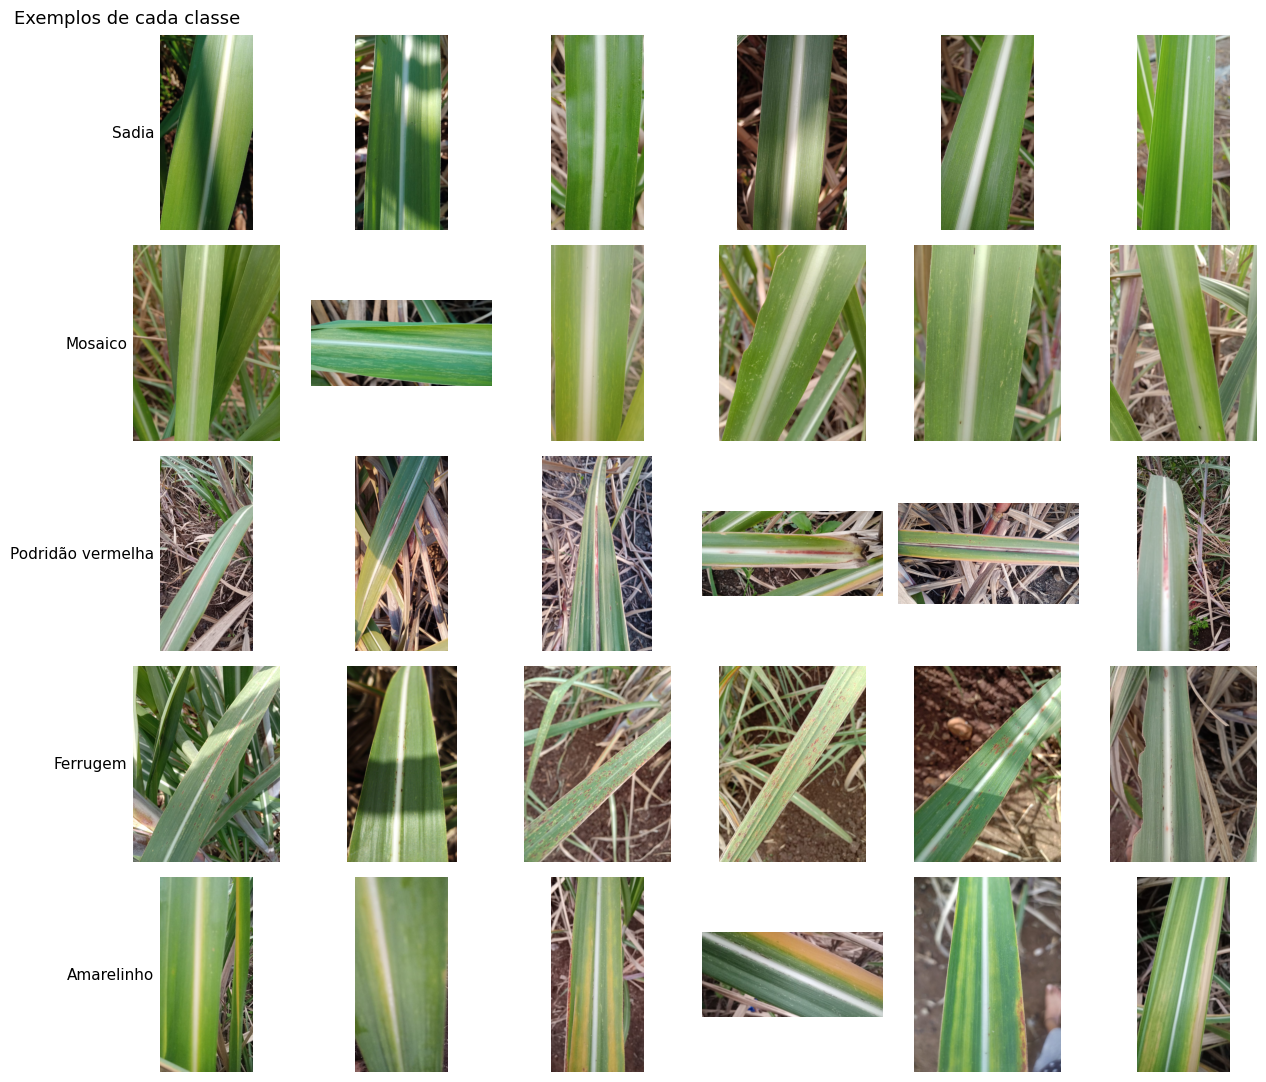

In [ ]:
N_POR_CLASSE = 6
fig, eixos = plt.subplots(len(CLASSES), N_POR_CLASSE, figsize=(13, 11))
for i, classe in enumerate(CLASSES):
    amostra = df[df['classe'] == classe].sample(N_POR_CLASSE, random_state=SEMENTE)
    for j, caminho in enumerate(amostra['caminho']):
        ax = eixos[i, j]
        ax.imshow(Image.open(caminho).convert('RGB'))
        ax.set_xticks([]); ax.set_yticks([])
        for lado in ax.spines.values(): lado.set_visible(False)
        if j == 0:
            ax.set_ylabel(classe, fontsize=11, rotation=0, ha='right', va='center')
plt.suptitle('Exemplos de cada classe', x=0.02, ha='left', fontsize=13)
plt.tight_layout(); plt.show()

### 2.3 Tamanho das imagens
As fotos vêm de **celulares diferentes**, então os tamanhos variam. Para padronizar a entrada dos modelos, as imagens foram recortadas e redimensionadas para **224 × 224 pixels**.

In [ ]:
def ler_tamanho(caminho):
    with Image.open(caminho) as img:          # abre só o cabeçalho, sem carregar a imagem inteira
        return img.size                       # (largura, altura)

tamanhos = df['caminho'].apply(ler_tamanho)
df['largura'] = tamanhos.str[0]
df['altura'] = tamanhos.str[1]
df['proporcao'] = (df['largura'] / df['altura']).round(2)

print('Resolução mais comuns (largura x altura):')
print((df['largura'].astype(str) + ' x ' + df['altura'].astype(str)).value_counts().head(8).to_string())
print()
print(df.groupby('classe')[['largura', 'altura']].median().reindex(CLASSES).astype(int))

Resolução mais comuns (largura x altura):
493 x 1040    958
780 x 1040    580
1040 x 493    217
585 x 1040    161
1040 x 780     75
758 x 1600     58
588 x 1280     50
899 x 1599     41

                   largura  altura
classe                            
Sadia                  493    1040
Mosaico                780    1040
Podridão vermelha      493     990
Ferrugem               780    1040
Amarelinho             493    1040


### 2.4 O tamanho da foto "denuncia" a doença?
A tabela acima mostra que a resolução mediana **muda conforme a classe**: as fotos de mosaico e ferrugem
foram tiradas, em boa parte, com um celular diferente das outras.

Essa associação pode produzir um **atalho de aprendizado**, baseado na resolução em vez de sintomas. O risco foi avaliado com uma árvore de decisão treinada **apenas com a largura e a altura** das fotografias.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Quantas fotos de cada resolução há em cada classe (só as 6 resoluções mais comuns)
res = df['largura'].astype(str) + ' x ' + df['altura'].astype(str)
principais = res.value_counts().index[:6]
tabela = pd.crosstab(res.where(res.isin(principais), 'outras').rename('resolução'), df['classe'])[CLASSES]
print(tabela, '\n')

# Modelo de controle usando apenas as dimensões (validação cruzada em 5 partes)
arvore = DecisionTreeClassifier(max_depth=6, random_state=SEMENTE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
acc_tamanho = cross_val_score(arvore, df[['largura', 'altura']], df['classe'], cv=cv).mean()

print(f'Referência aleatória uniforme (5 classes):       {1/len(CLASSES):.0%}')
print(f'Acurácia usando apenas o tamanho da foto:   {acc_tamanho:.0%}')

classe      Sadia  Mosaico  Podridão vermelha  Ferrugem  Amarelinho
resolução                                                          
1040 x 493     40       43                 57         0          77
1040 x 780      0        3                  0        72           0
493 x 1040    300      115                170         0         373
585 x 1040     92       23                 21         0          25
758 x 1600     13        0                 45         0           0
780 x 1040      0      263                  0       317           0
outras         77       15                225       125          30 

Acurácia "chutando" (5 classes):       20%
Acurácia usando SÓ o tamanho da foto:   56%


### Fase 2: o que observamos
1. **2.521 imagens** em 5 classes **equilibradas** (18% a 21% cada): a acurácia global é informativa, embora também seja necessária a avaliação por classe.
   *(A página da base cita 2.569; o arquivo baixado tem 2.521, mesmo número citado em outro artigo.)*
2. As fotos são de campo real: **fundo de palha, terra, outras folhas e luz variável**. Essas variações tornam a tarefa de classificação mais complexa.
3. **Achado importante:** a resolução da foto está ligada à classe. Só pelo tamanho da imagem, sem olhar a folha,
   um modelo simples acerta **cerca de 56%** (uma escolha aleatória uniforme teria 20% de acerto). É um **atalho** que a rede poderia aprender.
4. **Tratamento adotado:** recorte do quadrado central seguido de redimensionamento para 224 × 224 pixels, evitando distorções associadas a diferentes proporções de imagem. A padronização elimina diferenças de dimensão na entrada, embora não descarte outros vieses de coleta.



---
## Fase 3 · Pré-processamento: duplicatas e divisão dos dados

### Verificação de duplicatas
Imagens idênticas ou quase idênticas em conjuntos distintos podem causar vazamento de dados e superestimar o desempenho em imagens não vistas.
Um estudo de 2025 que juntou bases de folha de cana encontrou mais de **2.800 duplicatas**.

### 3.1 Duplicatas exatas
Foi calculado o **hash MD5** de cada arquivo para identificar cópias byte a byte.

In [ ]:
import hashlib

def md5_do_arquivo(caminho):
    with open(caminho, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

df['md5'] = df['caminho'].apply(md5_do_arquivo)
copias_exatas = df.duplicated('md5').sum()            # quantas são cópias de uma foto anterior
print(f'Cópias exatas encontradas: {copias_exatas} de {len(df)} imagens ({copias_exatas/len(df):.1%})')

# Verificação de hashes idênticos com classes diferentes
conflito = df.groupby('md5')['classe'].nunique().gt(1).sum()
print(f'Fotos idênticas com rótulos diferentes: {conflito}')

Cópias exatas encontradas: 210 de 2521 imagens (8.3%)
Fotos idênticas com rótulos diferentes: 0


### 3.2 Duplicatas "quase iguais"
Fotos tiradas em sequência da mesma folha não são idênticas no arquivo, mas são praticamente a mesma imagem.
Foi utilizado o **hash perceptual (pHash)**, que representa aspectos visuais em 64 bits. A similaridade foi avaliada pela distância de Hamming. Critério adotado: **mesma classe e distância ≤ 8 bits** (limite calibrado olhando os pares encontrados).

In [ ]:
%pip install -q imagehash
import imagehash

def phash(caminho):
    with Image.open(caminho) as img:
        return imagehash.phash(img.convert('RGB'))       # 64 bits que descrevem a aparência

hashes = [phash(c) for c in df['caminho']]              # um hash para cada foto

# Matriz de distâncias entre todos os pares (2.521 x 2.521): nº de bits diferentes
bits = np.array([h.hash.flatten() for h in hashes])
distancias = (bits[:, None, :] != bits[None, :, :]).sum(axis=2)

LIMITE = 8
rotulos = df['classe'].to_numpy(dtype=str)
mesma_classe = rotulos[:, None] == rotulos[None, :]                            # True se mesma doença
i_idx, j_idx = np.where(np.triu((distancias <= LIMITE) & mesma_classe, k=1))   # pares (i<j)
print(f'Pares de fotos quase iguais (mesma classe, distância ≤ {LIMITE}): {len(i_idx)}')

Pares de fotos quase iguais (mesma classe, distância ≤ 8): 285


In [ ]:
# Agrupa as duplicatas em grupos: se A~B e B~C, então A, B e C são uma família só.
# Técnica: union-find (cada foto aponta para um representante da família)
representante = list(range(len(df)))

def raiz(x):
    while representante[x] != x:
        representante[x] = representante[representante[x]]
        x = representante[x]
    return x

for a, b in zip(i_idx, j_idx):
    representante[raiz(b)] = raiz(a)

df['familia'] = [raiz(k) for k in range(len(df))]
df_limpo = df.drop_duplicates('familia').reset_index(drop=True)   # fica 1 foto por família

removidas = len(df) - len(df_limpo)
print(f'Imagens originais: {len(df)}')
print(f'Removidas (cópias e quase cópias): {removidas} ({removidas/len(df):.1%})')
print(f'Imagens únicas para modelar: {len(df_limpo)}')
print()
print(pd.DataFrame({'antes': df['classe'].value_counts(), 'depois': df_limpo['classe'].value_counts()}).reindex(CLASSES))

Imagens originais: 2521
Removidas (cópias e quase cópias): 236 (9.4%)
Imagens únicas para modelar: 2285

                   antes  depois
classe                          
Sadia                522     472
Mosaico              462     375
Podridão vermelha    518     504
Ferrugem             514     440
Amarelinho           505     494


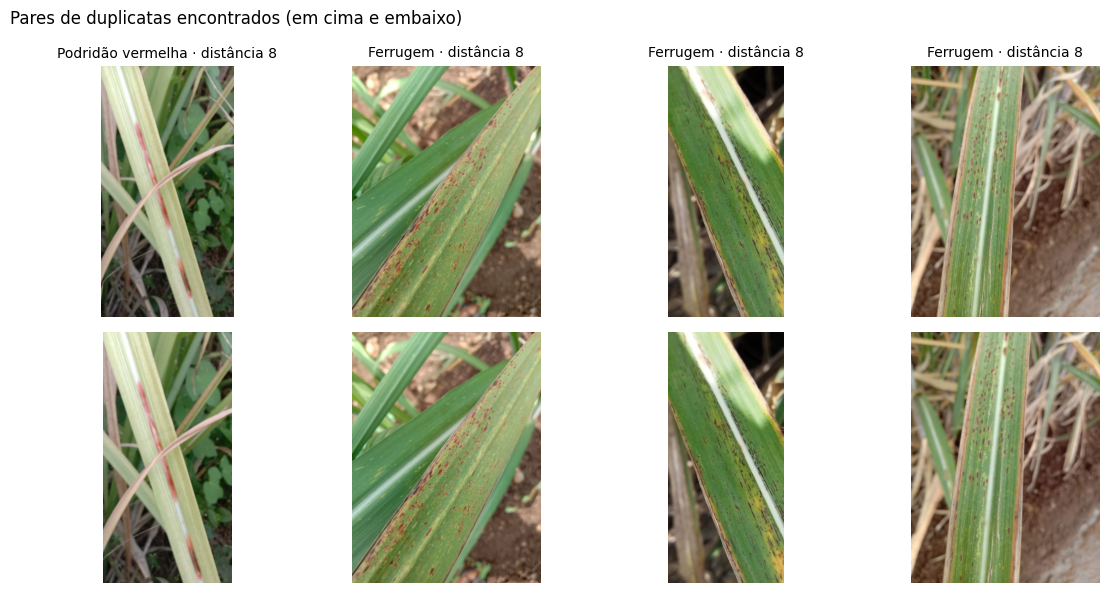

In [ ]:
# Mostra 4 exemplos de pares considerados duplicatas
# prioriza pares "quase iguais" (distância > 0), que são os mais difíceis de perceber a olho
pares = sorted(zip(i_idx, j_idx), key=lambda p: -distancias[p[0], p[1]])
exemplos = [p for p in pares if distancias[p[0], p[1]] > 0][:4]
fig, eixos = plt.subplots(2, 4, figsize=(12, 6))
for k, (a, b) in enumerate(exemplos):
    for linha, idx in enumerate([a, b]):
        ax = eixos[linha, k]
        ax.imshow(Image.open(df['caminho'][idx]).convert('RGB')); ax.axis('off')
    eixos[0, k].set_title(f"{df['classe'][a]} · distância {distancias[a, b]}", fontsize=10)
plt.suptitle('Pares de duplicatas encontrados (em cima e embaixo)', x=0.02, ha='left')
plt.tight_layout(); plt.show()

### 3.3 Divisão treino / validação / teste (70% / 15% / 15%)
- **Treino (70%)**: usado no ajuste dos parâmetros da rede.
- **Validação (15%)**: usada durante o treino para escolher a melhor época e evitar overfitting.
- **Teste (15%)**: reservado para a avaliação final de generalização no conjunto separado.

A divisão é **estratificada**: cada parte mantém a mesma proporção de cada doença.
A divisão foi realizada **após** a remoção de duplicatas e **antes** do aumento de dados.

In [ ]:
from sklearn.model_selection import train_test_split

# Primeira divisão: 70% treino e 30% restante
treino, resto = train_test_split(df_limpo, test_size=0.30, stratify=df_limpo['classe'], random_state=SEMENTE)
# Segunda divisão: 15% validação e 15% teste
validacao, teste = train_test_split(resto, test_size=0.50, stratify=resto['classe'], random_state=SEMENTE)

for nome, parte in [('treino', treino), ('validacao', validacao), ('teste', teste)]:
    df_limpo.loc[parte.index, 'conjunto'] = nome

print(pd.crosstab(df_limpo['classe'], df_limpo['conjunto'], margins=True, margins_name='total')
        .reindex(CLASSES + ['total'])[['treino', 'validacao', 'teste', 'total']])

# Garantia: nenhuma família de duplicatas aparece em mais de um conjunto
assert df_limpo.groupby('familia')['conjunto'].nunique().max() == 1

# Salva a divisão no Drive: registro dos conjuntos utilizados no experimento
df_limpo[['caminho', 'classe', 'conjunto']].to_csv(os.path.join(PASTA_DRIVE, 'divisao_dados.csv'), index=False)
print('\nDivisão salva em divisao_dados.csv')

conjunto           treino  validacao  teste  total
classe                                            
Sadia                 330         71     71    472
Mosaico               262         56     57    375
Podridão vermelha     353         76     75    504
Ferrugem              308         66     66    440
Amarelinho            346         74     74    494
total                1599        343    343   2285

Divisão salva em divisao_dados.csv


> **Controle de qualidade dos dados:** duplicatas exatas e imagens muito semelhantes foram removidas antes da divisão entre treinamento, validação e teste, reduzindo o risco de vazamento de informação e superestimação do desempenho.


---
## Fase 4 · Preparar as imagens para a rede

### 4.1 Recorte central + redimensionamento
A análise exploratória mostrou dimensões diferentes entre as classes. Foram aplicadas as seguintes etapas para padronizar a entrada:
1. **Recorte do quadrado central** (lado = menor dimensão da foto), que preserva a região central da imagem;
2. **Redimensionamento para 224 × 224 pixels**, tamanho padrão da MobileNetV2.

Os pixels são carregados no intervalo **0 a 255**, com normalização específica em cada arquitetura.

In [ ]:
import tensorflow as tf

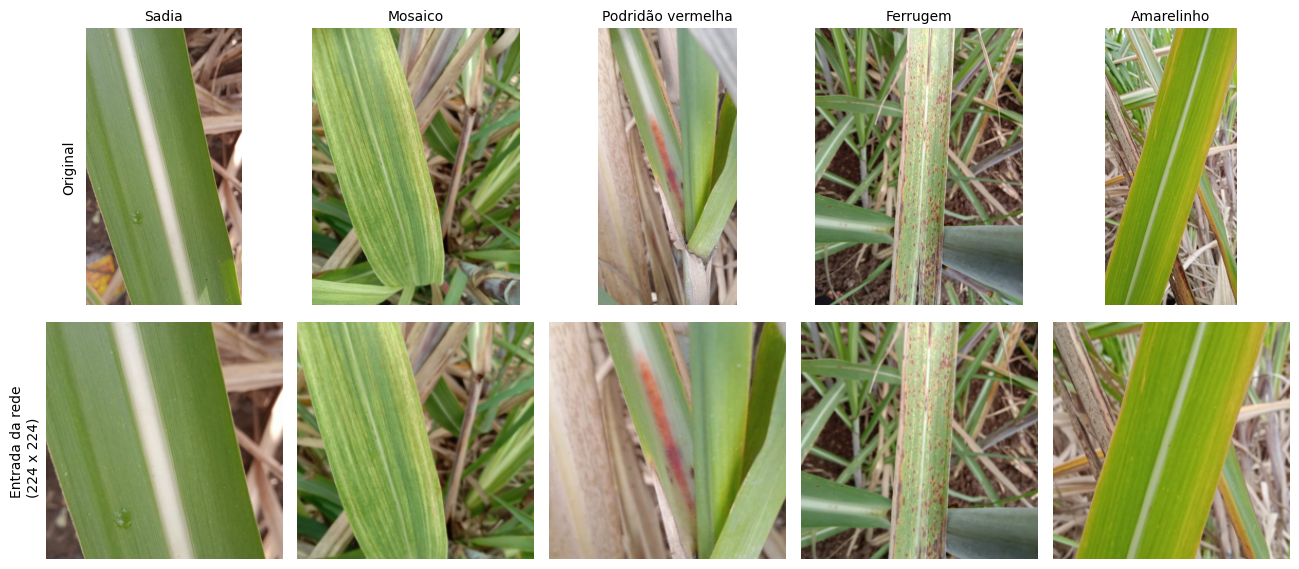

In [ ]:
TAMANHO = 224                   # lado da imagem que entra na rede (pixels)

def carregar_imagem(caminho):
    """Lê o arquivo, recorta o quadrado central e redimensiona para 224x224."""
    bruto = tf.io.read_file(caminho)
    img = tf.io.decode_jpeg(bruto, channels=3)                      # 3 canais: R, G, B
    h, w = tf.shape(img)[0], tf.shape(img)[1]
    lado = tf.minimum(h, w)                                         # lado do quadrado
    topo, esquerda = (h - lado) // 2, (w - lado) // 2
    img = tf.image.crop_to_bounding_box(img, topo, esquerda, lado, lado)
    img = tf.image.resize(img, (TAMANHO, TAMANHO), antialias=True)  # suaviza ao reduzir
    return tf.cast(img, tf.float32)                                 # 0 a 255, tipo decimal

# Comparação visual: foto original x imagem após o pré-processamento
fig, eixos = plt.subplots(2, 5, figsize=(13, 6))
for k, classe in enumerate(CLASSES):
    caminho = treino[treino['classe'] == classe]['caminho'].iloc[0]
    eixos[0, k].imshow(Image.open(caminho).convert('RGB')); eixos[0, k].set_title(classe, fontsize=10)
    eixos[1, k].imshow(carregar_imagem(caminho).numpy().astype('uint8'))
    eixos[0, k].axis('off'); eixos[1, k].axis('off')
eixos[0, 0].text(-0.15, 0.5, 'Original', transform=eixos[0, 0].transAxes, rotation=90, va='center')
eixos[1, 0].text(-0.15, 0.5, 'Entrada da rede\n(224 x 224)', transform=eixos[1, 0].transAxes, rotation=90, va='center')
plt.tight_layout(); plt.show()

### 4.2 Codificação dos rótulos
Os rótulos das cinco classes foram codificados como inteiros de **0 a 4**, na ordem definida por `CLASSES`. A saída dos modelos utiliza **softmax** com cinco unidades.

In [ ]:
INDICE = {classe: i for i, classe in enumerate(CLASSES)}
print(INDICE)

{'Sadia': 0, 'Mosaico': 1, 'Podridão vermelha': 2, 'Ferrugem': 3, 'Amarelinho': 4}


### 4.3 Pipeline de dados (`tf.data`)
O `tf.data` carrega as imagens em **lotes (batches)** de 32, em paralelo, e guarda em memória (`cache`) após a primeira leitura.
O pré-carregamento reduz esperas entre as etapas de leitura e treinamento.

In [ ]:
LOTE = 32
AUTOTUNE = tf.data.AUTOTUNE

def criar_dataset(parte, embaralhar=False):
    caminhos = parte['caminho'].values
    rotulos = parte['classe'].map(INDICE).values
    ds = tf.data.Dataset.from_tensor_slices((caminhos, rotulos))
    ds = ds.map(lambda c, r: (carregar_imagem(c), r), num_parallel_calls=AUTOTUNE)
    ds = ds.cache()                                   # guarda as imagens já processadas
    if embaralhar:
        ds = ds.shuffle(len(parte), seed=SEMENTE)     # nova ordem a cada época (só no treino)
    return ds.batch(LOTE).prefetch(AUTOTUNE)          # prepara o próximo lote enquanto a GPU treina

ds_treino = criar_dataset(treino, embaralhar=True)
ds_val = criar_dataset(validacao)
ds_teste = criar_dataset(teste)

imgs, rots = next(iter(ds_treino))
print('Formato de um lote de imagens:', imgs.shape, '→ (fotos, altura, largura, canais)')
print('Rótulos do lote:', rots.numpy()[:10], '...')

Formato de um lote de imagens: (32, 224, 224, 3) → (fotos, altura, largura, canais)
Rótulos do lote: [0 0 4 2 2 0 1 1 0 0] ...


### 4.4 Aumento de dados (data augmentation)
Para aumentar a variedade das aproximadamente 1.600 imagens de treinamento, foram utilizadas transformações aleatórias de espelhamento, rotação, zoom, brilho e contraste. As transformações são aplicadas **apenas no treinamento**, não na validação ou no teste.

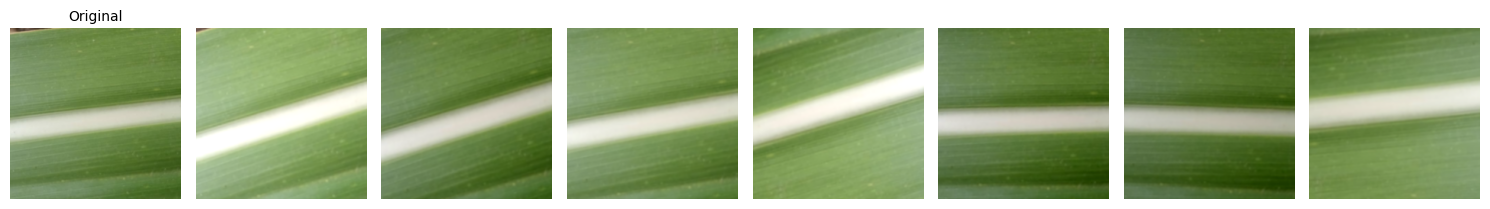

In [ ]:
aumento = keras.Sequential([
    keras.layers.RandomFlip('horizontal_and_vertical'),  # espelha (a folha pode estar em qualquer sentido)
    keras.layers.RandomRotation(0.03),                    # gira até ±11 graus
    keras.layers.RandomZoom((-0.25, -0.10)),              # aproxima 10% a 25% (esconde os cantos do giro)
    keras.layers.RandomContrast(0.2),                     # varia o contraste (luz do campo)
    keras.layers.RandomBrightness(0.15, value_range=(0, 255)),  # varia o brilho (sol/sombra)
], name='aumento_de_dados')

# Mostra 1 foto e 7 variações geradas
foto = imgs[0]
fig, eixos = plt.subplots(1, 8, figsize=(15, 2.4))
eixos[0].imshow(foto.numpy().astype('uint8')); eixos[0].set_title('Original', fontsize=10)
for k in range(1, 8):
    variacao = aumento(foto[None, ...], training=True)[0]
    eixos[k].imshow(np.clip(variacao.numpy(), 0, 255).astype('uint8'))
for ax in eixos: ax.axis('off')
plt.tight_layout(); plt.show()

> **Padronização de entrada:** as imagens foram recortadas pelo centro e redimensionadas para 224 × 224 pixels. As transformações aleatórias foram aplicadas apenas durante o treinamento.


---
## Fase 5 · Modelo 1: CNN construída do zero

### Arquitetura e componentes
- **Camada convolucional (Conv2D)**: filtros de 3 × 3 pixels extraem características locais, como bordas, texturas e padrões de lesões.
- **BatchNormalization**: normaliza ativações intermediárias e favorece a estabilidade do treinamento.
- **ReLU**: função de ativação; introduz não linearidade nas ativações.
- **MaxPooling**: reduz as dimensões espaciais, preservando ativações máximas por região.
- **GlobalAveragePooling**: resume cada mapa de características por média espacial.
- **Dropout**: desativa aleatoriamente unidades durante o treinamento para regularização.
- **Dense + softmax (5 neurônios)**: produz as probabilidades associadas às cinco classes.

### Normalização
As imagens chegam com pixels de 0 a 255. A camada `Rescaling(1/255)` converte para **0 a 1**,
faixa em que o treino da rede é mais estável.

In [ ]:
def bloco_conv(x, filtros):
    """Um bloco: convolução 3x3 -> normalização -> ReLU -> reduz pela metade."""
    x = keras.layers.Conv2D(filtros, 3, padding='same', use_bias=False)(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.ReLU()(x)
    return keras.layers.MaxPooling2D()(x)

entrada = keras.Input(shape=(TAMANHO, TAMANHO, 3), name='foto')
x = aumento(entrada)                                  # variações aleatórias (só no treino)
x = keras.layers.Rescaling(1/255, name='normalizacao_0a1')(x)
for filtros in [32, 64, 128, 256]:                    # 4 blocos: cada um aprende padrões mais complexos
    x = bloco_conv(x, filtros)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.4)(x)
saida = keras.layers.Dense(len(CLASSES), activation='softmax', name='probabilidades')(x)

modelo1 = keras.Model(entrada, saida, name='cnn_do_zero')
modelo1.summary()

Model: "cnn_do_zero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ foto (InputLayer)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_de_dados (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao_0a1 (Rescaling)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidades (Dense)          │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 391,141 (1.49 MB)

 Trainable params: 390,181 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

### Treinamento
- **Otimizador Adam** (taxa de aprendizado 0,001): otimiza os parâmetros ao longo do treinamento.
- **Função de perda `sparse_categorical_crossentropy`**: função de perda para classificação multiclasse com rótulos inteiros.
- **EarlyStopping**: interrompe o treinamento em caso de estagnação da acurácia de validação e restaura os melhores pesos.
- **ReduceLROnPlateau**: se a perda de validação estagnar, reduz a taxa de aprendizado para favorecer ajustes menores.

O treinamento foi realizado no Google Colab com GPU NVIDIA T4.

In [ ]:
%%time
def callbacks_padrao(paciencia=8):
    return [
        keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=paciencia,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3,
                                          min_lr=1e-6, verbose=1),
    ]

modelo1.compile(optimizer=keras.optimizers.Adam(1e-3),
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])

historico1 = modelo1.fit(ds_treino, validation_data=ds_val, epochs=40,
                         callbacks=callbacks_padrao(), verbose=2)

Epoch 1/40
50/50 - 20s - 392ms/step - accuracy: 0.6185 - loss: 0.9825 - val_accuracy: 0.1953 - val_loss: 2.4391 - learning_rate: 0.0010
Epoch 2/40
50/50 - 7s - 140ms/step - accuracy: 0.6717 - loss: 0.8776 - val_accuracy: 0.2420 - val_loss: 2.2894 - learning_rate: 0.0010
Epoch 3/40
50/50 - 7s - 148ms/step - accuracy: 0.6973 - loss: 0.8146 - val_accuracy: 0.1720 - val_loss: 2.6304 - learning_rate: 0.0010
Epoch 4/40
50/50 - 7s - 141ms/step - accuracy: 0.6979 - loss: 0.7644 - val_accuracy: 0.1720 - val_loss: 2.7109 - learning_rate: 0.0010
Epoch 5/40

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
50/50 - 7s - 145ms/step - accuracy: 0.7186 - loss: 0.7275 - val_accuracy: 0.1983 - val_loss: 2.6641 - learning_rate: 0.0010
Epoch 6/40
50/50 - 7s - 139ms/step - accuracy: 0.7498 - loss: 0.6541 - val_accuracy: 0.1953 - val_loss: 2.5780 - learning_rate: 5.0000e-04
Epoch 7/40
50/50 - 7s - 142ms/step - accuracy: 0.7573 - loss: 0.6663 - val_accuracy: 0.2332 - val_loss: 2.26

### Curvas de treinamento e validação
As curvas de acurácia e perda foram utilizadas para acompanhar a convergência e investigar possíveis diferenças de desempenho entre treinamento e validação (sobreajuste).

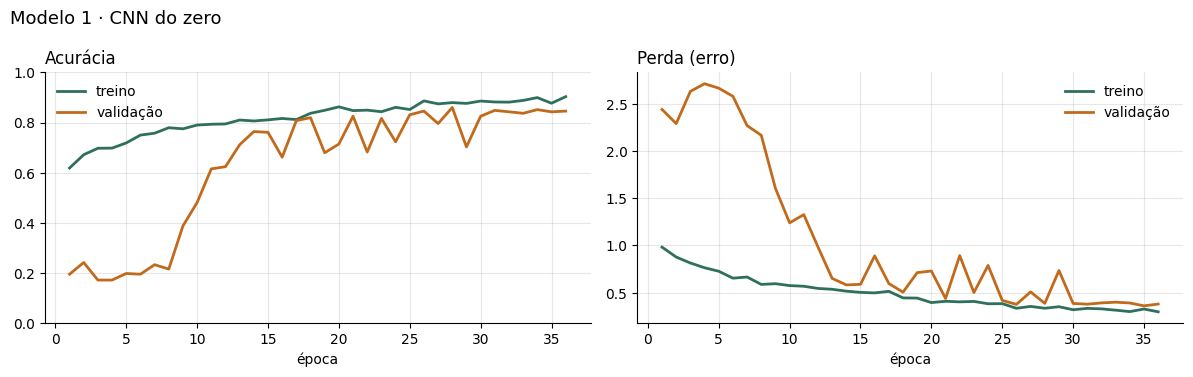

Melhor acurácia de validação (Modelo 1): 86.0%


In [ ]:
def plotar_historico(historico, titulo):
    h = historico.history
    epocas = range(1, len(h['loss']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
    ax1.plot(epocas, h['accuracy'], color='#2f6f5e', lw=2, label='treino')
    ax1.plot(epocas, h['val_accuracy'], color='#c26a1b', lw=2, label='validação')
    ax1.set_title('Acurácia', loc='left'); ax1.set_xlabel('época'); ax1.set_ylim(0, 1)
    ax2.plot(epocas, h['loss'], color='#2f6f5e', lw=2, label='treino')
    ax2.plot(epocas, h['val_loss'], color='#c26a1b', lw=2, label='validação')
    ax2.set_title('Perda (erro)', loc='left'); ax2.set_xlabel('época')
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3); ax.legend(frameon=False)
    fig.suptitle(titulo, x=0.01, ha='left', fontsize=13)
    plt.tight_layout(); plt.show()

plotar_historico(historico1, 'Modelo 1 · CNN do zero')
_, acc_val1 = modelo1.evaluate(ds_val, verbose=0)
print(f'Melhor acurácia de validação (Modelo 1): {acc_val1:.1%}')

# Salva o modelo treinado no Drive
modelo1.save(os.path.join(PASTA_DRIVE, 'modelo1_cnn_do_zero.keras'))

> **Modelo de referência:** a CNN com quatro blocos convolucionais foi treinada do zero para permitir a comparação com as estratégias de transferência de aprendizado.


---
## Fase 6 · Modelos 2 e 3: transfer learning com MobileNetV2

### Estratégia de transferência de aprendizado
A **MobileNetV2** é uma rede criada pelo Google e já treinada com **1,4 milhão de fotos** (base ImageNet, 1.000 categorias).
Os pesos pré-treinados foram reutilizados para extrair características visuais; o classificador final foi adaptado às cinco classes. A arquitetura foi escolhida também por sua eficiência computacional, relevante para uma possível implementação móvel futura.

### Normalização específica
A MobileNetV2 foi treinada com pixels na faixa **−1 a 1**. Foi utilizada a transformação `Rescaling(1/127.5, offset=-1)`:
0 → −1, 255 → +1.

In [ ]:
base = keras.applications.MobileNetV2(input_shape=(TAMANHO, TAMANHO, 3),
                                      include_top=False,      # sem a camada final das 1.000 categorias
                                      weights='imagenet')     # pesos já treinados
base.trainable = False                                        # Modelo 2: base CONGELADA
print(f'Camadas da MobileNetV2: {len(base.layers)} | parâmetros: {base.count_params():,}'.replace(',', '.'))

entrada = keras.Input(shape=(TAMANHO, TAMANHO, 3), name='foto')
x = aumento(entrada)
x = keras.layers.Rescaling(1/127.5, offset=-1, name='normalizacao_menos1a1')(x)
x = base(x, training=False)            # training=False: mantém as estatísticas internas da base fixas
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)
saida = keras.layers.Dense(len(CLASSES), activation='softmax', name='probabilidades')(x)

modelo2 = keras.Model(entrada, saida, name='mobilenetv2_congelada')
treinaveis = sum(np.prod(p.shape) for p in modelo2.trainable_weights)
print(f'Parâmetros que serão treinados: {treinaveis:,} (só a camada final)'.replace(',', '.'))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Camadas da MobileNetV2: 154 | parâmetros: 2.257.984
Parâmetros que serão treinados: 6.405 (só a camada final)


### Modelo 2: treinamento do classificador final
Com a base congelada, apenas a última camada (cerca de 6 mil parâmetros) é treinada, preservando as características da base pré-treinada.

Epoch 1/25
50/50 - 15s - 291ms/step - accuracy: 0.4872 - loss: 1.2738 - val_accuracy: 0.6735 - val_loss: 0.8336 - learning_rate: 0.0010
Epoch 2/25
50/50 - 4s - 77ms/step - accuracy: 0.7011 - loss: 0.8145 - val_accuracy: 0.7318 - val_loss: 0.7027 - learning_rate: 0.0010
Epoch 3/25
50/50 - 4s - 79ms/step - accuracy: 0.7523 - loss: 0.6846 - val_accuracy: 0.8222 - val_loss: 0.5916 - learning_rate: 0.0010
Epoch 4/25
50/50 - 4s - 83ms/step - accuracy: 0.7717 - loss: 0.6164 - val_accuracy: 0.8047 - val_loss: 0.5487 - learning_rate: 0.0010
Epoch 5/25
50/50 - 4s - 79ms/step - accuracy: 0.7911 - loss: 0.5631 - val_accuracy: 0.8309 - val_loss: 0.5219 - learning_rate: 0.0010
Epoch 6/25
50/50 - 4s - 75ms/step - accuracy: 0.8318 - loss: 0.4883 - val_accuracy: 0.7872 - val_loss: 0.5608 - learning_rate: 0.0010
Epoch 7/25
50/50 - 4s - 79ms/step - accuracy: 0.8249 - loss: 0.4814 - val_accuracy: 0.7843 - val_loss: 0.5816 - learning_rate: 0.0010
Epoch 8/25
50/50 - 4s - 80ms/step - accuracy: 0.8299 - loss:

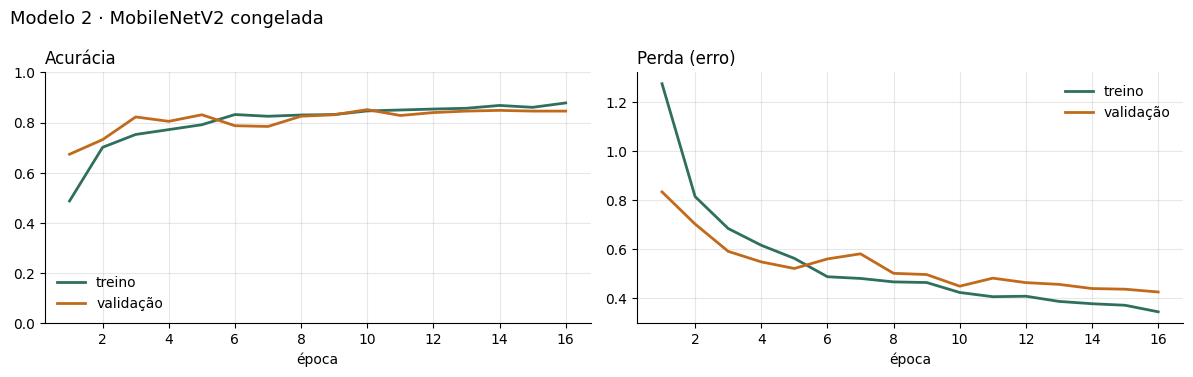

Melhor acurácia de validação (Modelo 2): 85.1%


In [ ]:
modelo2.compile(optimizer=keras.optimizers.Adam(1e-3),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])

historico2 = modelo2.fit(ds_treino, validation_data=ds_val, epochs=25,
                         callbacks=callbacks_padrao(paciencia=6), verbose=2)

plotar_historico(historico2, 'Modelo 2 · MobileNetV2 congelada')
_, acc_val2 = modelo2.evaluate(ds_val, verbose=0)
print(f'Melhor acurácia de validação (Modelo 2): {acc_val2:.1%}')
modelo2.save(os.path.join(PASTA_DRIVE, 'modelo2_mobilenet_congelada.keras'))

### Modelo 3: ajuste fino (fine-tuning)
O Modelo 2 treinado foi utilizado como ponto de partida, com **descongelamento das camadas finais da MobileNetV2** (a partir do bloco 13),
para adaptação às imagens das folhas.

Configuração adotada:
- **Taxa de aprendizado 100 vezes menor** (0,00001): para limitar alterações nos pesos pré-treinados.
- As primeiras camadas (características visuais gerais) continuam congeladas.

Camadas liberadas: 38 de 154
Parâmetros treináveis agora: 1.669.765
Epoch 1/25
50/50 - 15s - 304ms/step - accuracy: 0.8568 - loss: 0.3974 - val_accuracy: 0.8688 - val_loss: 0.4081 - learning_rate: 1.0000e-05
Epoch 2/25
50/50 - 4s - 88ms/step - accuracy: 0.8668 - loss: 0.3700 - val_accuracy: 0.8571 - val_loss: 0.3975 - learning_rate: 1.0000e-05
Epoch 3/25
50/50 - 4s - 87ms/step - accuracy: 0.8787 - loss: 0.3275 - val_accuracy: 0.8571 - val_loss: 0.3604 - learning_rate: 1.0000e-05
Epoch 4/25
50/50 - 5s - 93ms/step - accuracy: 0.8912 - loss: 0.2993 - val_accuracy: 0.8834 - val_loss: 0.3413 - learning_rate: 1.0000e-05
Epoch 5/25
50/50 - 5s - 91ms/step - accuracy: 0.9081 - loss: 0.2714 - val_accuracy: 0.8950 - val_loss: 0.3092 - learning_rate: 1.0000e-05
Epoch 6/25
50/50 - 4s - 89ms/step - accuracy: 0.9043 - loss: 0.2655 - val_accuracy: 0.9038 - val_loss: 0.2923 - learning_rate: 1.0000e-05
Epoch 7/25
50/50 - 5s - 91ms/step - accuracy: 0.9024 - loss: 0.2482 - val_accuracy: 0.8630 - val_loss:

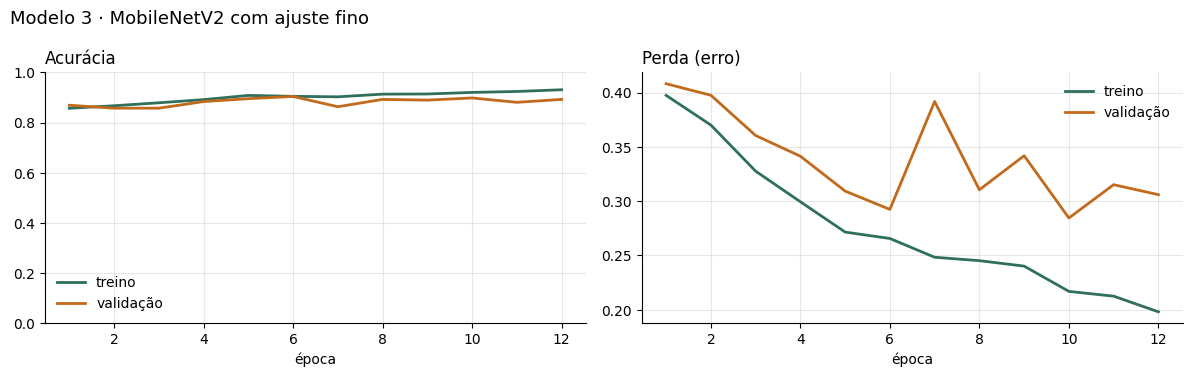

Melhor acurácia de validação (Modelo 3): 90.4%


In [ ]:
modelo3 = keras.models.load_model(os.path.join(PASTA_DRIVE, 'modelo2_mobilenet_congelada.keras'))
modelo3.name = 'mobilenetv2_ajuste_fino'
base3 = [camada for camada in modelo3.layers if camada.name.startswith('mobilenetv2')][0]   # a MobileNetV2 dentro do modelo

base3.trainable = True
nomes = [camada.name for camada in base3.layers]
inicio = nomes.index('block_13_expand')                     # libera do bloco 13 até o fim
for camada in base3.layers[:inicio]:
    camada.trainable = False
for camada in base3.layers:                                 # normalização interna continua congelada
    if isinstance(camada, keras.layers.BatchNormalization):
        camada.trainable = False

treinaveis = sum(np.prod(p.shape) for p in modelo3.trainable_weights)
print(f'Camadas liberadas: {len(base3.layers) - inicio} de {len(base3.layers)}')
print(f'Parâmetros treináveis agora: {treinaveis:,}'.replace(',', '.'))

modelo3.compile(optimizer=keras.optimizers.Adam(1e-5),    # taxa 100x menor
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])

historico3 = modelo3.fit(ds_treino, validation_data=ds_val, epochs=25,
                         callbacks=callbacks_padrao(paciencia=6), verbose=2)

plotar_historico(historico3, 'Modelo 3 · MobileNetV2 com ajuste fino')
_, acc_val3 = modelo3.evaluate(ds_val, verbose=0)
print(f'Melhor acurácia de validação (Modelo 3): {acc_val3:.1%}')
modelo3.save(os.path.join(PASTA_DRIVE, 'modelo3_mobilenet_ajuste_fino.keras'))

> **Transferência de aprendizado:** a MobileNetV2 foi avaliada com a base congelada e, posteriormente, com ajuste fino das camadas finais, utilizando uma taxa de aprendizado reduzida.


---
## Fase 7 · Avaliação no conjunto de teste
A avaliação final utilizou **343 imagens separadas** do treinamento e da validação. Esse conjunto foi reservado para estimar o desempenho em fotografias não utilizadas no ajuste dos modelos.

### 7.1 Comparação dos três modelos

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

y_teste = teste['classe'].map(INDICE).values               # respostas certas, na ordem do ds_teste

resultados = []
previsoes = {}
for nome, modelo in [('1 · CNN do zero', modelo1),
                     ('2 · MobileNetV2 congelada', modelo2),
                     ('3 · MobileNetV2 ajuste fino', modelo3)]:
    prob = modelo.predict(ds_teste, verbose=0)               # probabilidades das 5 classes
    pred = prob.argmax(axis=1)                               # classe com maior probabilidade
    previsoes[nome] = (prob, pred)
    resultados.append({'modelo': nome,
                       'acurácia': (pred == y_teste).mean(),
                       'F1 macro': f1_score(y_teste, pred, average='macro'),
                       'parâmetros': modelo.count_params()})

tabela = pd.DataFrame(resultados).set_index('modelo')
referencia = pd.DataFrame({'acurácia': [0.84, 0.865]},
                          index=['Artigo: MobileNetV2 (Daphal & Koli, 2023)', 'Artigo: ensemble (Daphal & Koli, 2023)'])
comparacao = pd.concat([tabela, referencia])
comparacao.style.format({'acurácia': '{:.1%}', 'F1 macro': '{:.3f}', 'parâmetros': '{:,.0f}'}, na_rep='–')

,acurácia,F1 macro,parâmetros
1 · CNN do zero,85.4%,0.852,"391,141"
2 · MobileNetV2 congelada,84.5%,0.845,"2,264,389"
3 · MobileNetV2 ajuste fino,88.3%,0.882,"2,264,389"
"Artigo: MobileNetV2 (Daphal & Koli, 2023)",84.0%,–,–
"Artigo: ensemble (Daphal & Koli, 2023)",86.5%,–,–


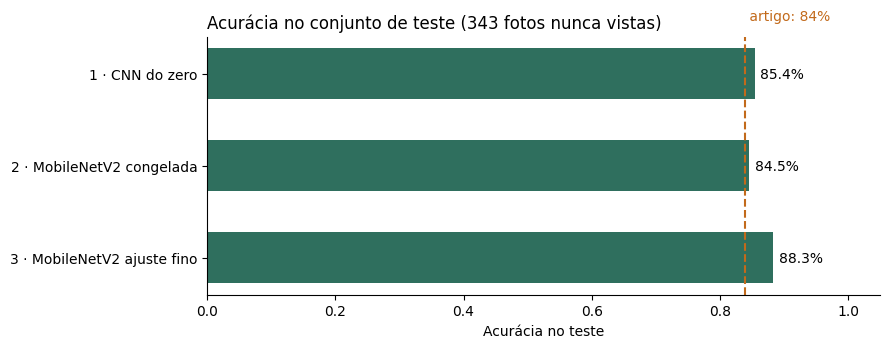

In [ ]:
# Gráfico de barras: modelos avaliados e referência da literatura
fig, ax = plt.subplots(figsize=(9, 3.6))
nomes = list(tabela.index)
valores = tabela['acurácia'].values
barras = ax.barh(nomes[::-1], valores[::-1], color='#2f6f5e', height=0.55)
ax.bar_label(barras, labels=[f'{v:.1%}' for v in valores[::-1]], padding=4)
ax.axvline(0.84, color='#c26a1b', ls='--', lw=1.5)
ax.text(0.84, len(nomes) - 0.45, ' artigo: 84%', color='#c26a1b', va='bottom')
ax.set_xlim(0, 1.05); ax.set_xlabel('Acurácia no teste')
ax.set_title('Acurácia no conjunto de teste (343 fotos nunca vistas)', loc='left')
plt.tight_layout(); plt.show()

### 7.2 Desempenho por classe (melhor modelo)
Foram avaliadas **precisão**, **recall (sensibilidade)** e **F1-score** para cada classe. Essas métricas permitem identificar assimetrias de desempenho que não aparecem na acurácia global. A importância operacional de falsos negativos e falsos positivos precisa ser avaliada em estudos de campo.

In [ ]:
melhor = tabela['acurácia'].idxmax()
prob_melhor, pred_melhor = previsoes[melhor]
print('Melhor modelo:', melhor, '\n')
print(classification_report(y_teste, pred_melhor, target_names=CLASSES, digits=3, zero_division=0))

Melhor modelo: 3 · MobileNetV2 ajuste fino 

                   precision    recall  f1-score   support

            Sadia      0.882     0.944     0.912        71
          Mosaico      0.862     0.877     0.870        57
Podridão vermelha      0.919     0.907     0.913        75
         Ferrugem      0.861     0.939     0.899        66
       Amarelinho      0.889     0.757     0.818        74

         accuracy                          0.883       343
        macro avg      0.883     0.885     0.882       343
     weighted avg      0.884     0.883     0.882       343



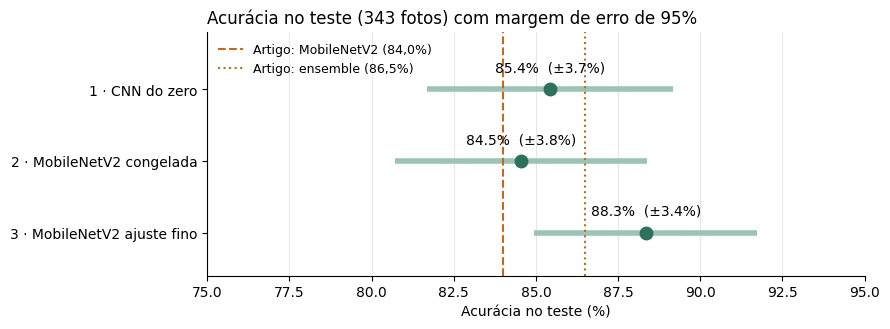

In [ ]:
# Gráfico de pontos: acurácia de cada modelo com a margem de erro de 95%
n = len(y_teste)                                      # 343 fotos de teste
acc = tabela['acurácia']
margem = 1.96 * np.sqrt(acc * (1 - acc) / n)          # margem de erro de 95% de cada acurácia

fig, ax = plt.subplots(figsize=(9, 3.4))
pos = np.arange(len(acc))[::-1]                       # modelo 1 em cima
ax.errorbar(acc * 100, pos, xerr=margem * 100, fmt='o', color='#2f6f5e',
            ecolor='#9cc3b5', elinewidth=4, markersize=9, capsize=0)
for p, v, m in zip(pos, acc, margem):
    ax.text(v * 100, p + 0.25, f'{v:.1%}  (±{m:.1%})', ha='center', fontsize=10)
ax.axvline(84.0, color='#c26a1b', ls='--', lw=1.5, label='Artigo: MobileNetV2 (84,0%)')
ax.axvline(86.5, color='#c26a1b', ls=':', lw=1.5, label='Artigo: ensemble (86,5%)')
ax.set_yticks(pos, acc.index)
ax.set_xlim(75, 95); ax.set_ylim(-0.6, len(acc) - 0.2)
ax.set_xlabel('Acurácia no teste (%)')
ax.set_title(f'Acurácia no teste ({n} fotos) com margem de erro de 95%', loc='left')
ax.legend(loc='upper left', frameon=False, fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

### 7.3 Matriz de confusão
A matriz apresenta as classes reais nas linhas e as classes previstas nas colunas. Os valores percentuais foram normalizados por linha, permitindo identificar os principais tipos de confusão.

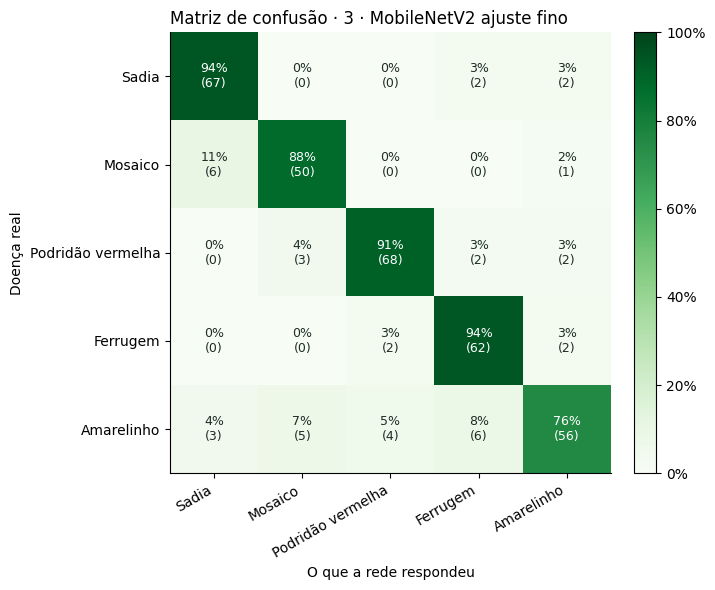

In [ ]:
mc = confusion_matrix(y_teste, pred_melhor)
mc_pct = mc / mc.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(mc_pct, cmap='Greens', vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        cor_texto = 'white' if mc_pct[i, j] > 0.6 else '#1f2d27'
        ax.text(j, i, f'{mc_pct[i, j]:.0%}\n({mc[i, j]})', ha='center', va='center', color=cor_texto, fontsize=9)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha='right')
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel('O que a rede respondeu'); ax.set_ylabel('Doença real')
ax.set_title(f'Matriz de confusão · {melhor}', loc='left')
plt.colorbar(im, fraction=0.046, pad=0.04, format=lambda v, _: f'{v:.0%}')
plt.tight_layout(); plt.show()

### 7.4 Análise qualitativa dos erros
Foram examinadas imagens classificadas incorretamente, incluindo casos com sintomas discretos, enquadramento complexo ou condições visuais desfavoráveis.

Erros: 40 de 343 fotos


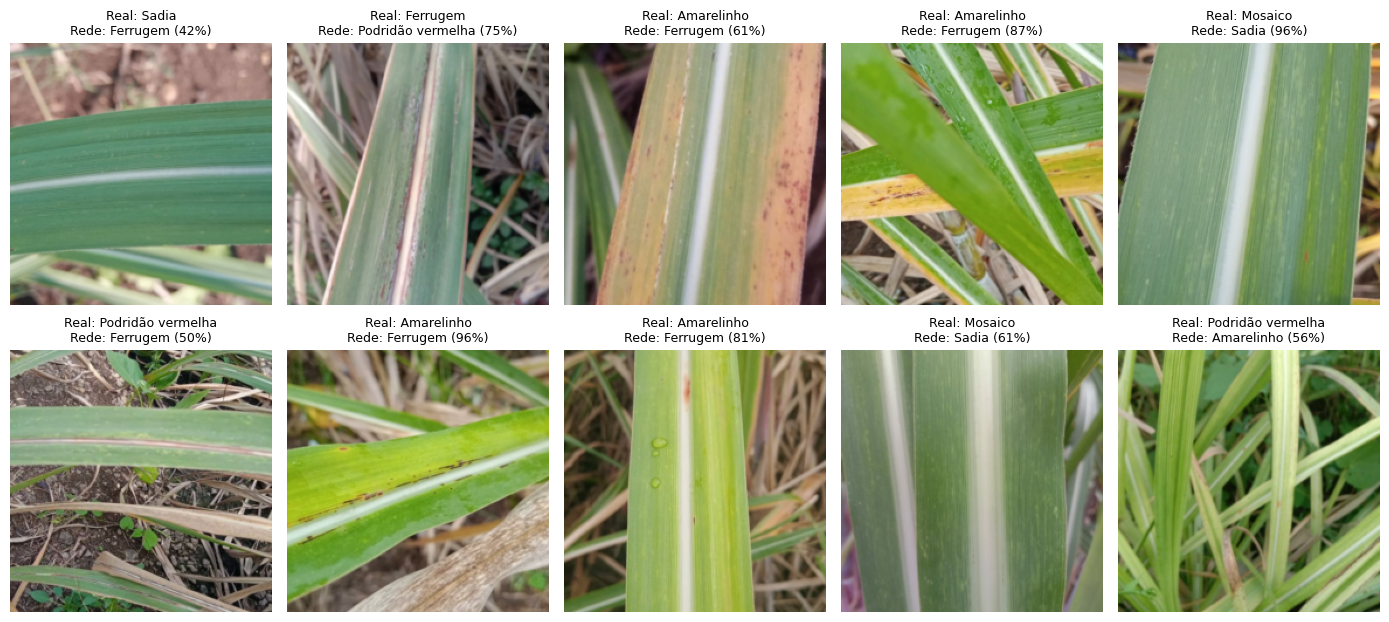

In [ ]:
erros = np.where(pred_melhor != y_teste)[0]
print(f'Erros: {len(erros)} de {len(y_teste)} fotos')
mostrar = erros[:10]
if len(mostrar):
    fig, eixos = plt.subplots(2, 5, figsize=(14, 6.5))
    for ax, k in zip(eixos.flat, mostrar):
        ax.imshow(carregar_imagem(teste['caminho'].iloc[k]).numpy().astype('uint8'))
        ax.set_title(f"Real: {CLASSES[y_teste[k]]}\nRede: {CLASSES[pred_melhor[k]]} ({prob_melhor[k].max():.0%})", fontsize=9)
    for ax in eixos.flat: ax.axis('off')
    plt.tight_layout(); plt.show()

### 7.5 Análise de atenção visual com Grad-CAM
O **Grad-CAM** produz mapas de calor para visualizar regiões que influenciam a previsão. A análise permite investigar a concentração da ativação na folha ou no fundo, **sem comprovar isoladamente que a decisão se baseia na lesão**. Os mapas são obtidos a partir dos gradientes do modelo em relação aos mapas de características da MobileNetV2.

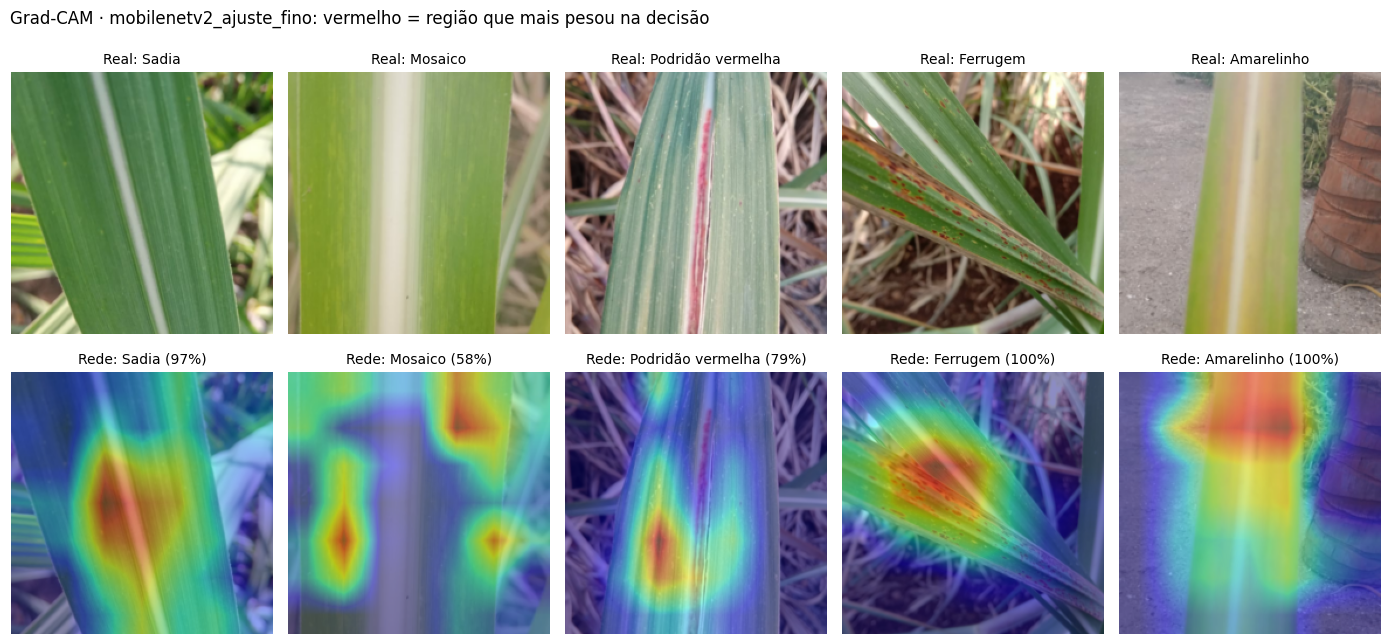

In [ ]:
def grad_cam(modelo, imagem):
    """Mapa de calor Grad-CAM para um modelo MobileNetV2 (modelos 2 e 3)."""
    base_ = [c for c in modelo.layers if c.name.startswith('mobilenetv2')][0]    # a MobileNetV2 interna
    normaliza = modelo.get_layer('normalizacao_menos1a1')
    gap = [c for c in modelo.layers if isinstance(c, keras.layers.GlobalAveragePooling2D)][0]
    densa = modelo.get_layer('probabilidades')
    with tf.GradientTape() as fita:
        mapas = base_(normaliza(imagem[None, ...]), training=False)   # 7x7x1280: mapas de características
        fita.watch(mapas)
        prob = densa(gap(mapas))
        classe = tf.argmax(prob[0])
        alvo = prob[0, classe]
    grad = fita.gradient(alvo, mapas)                                 # sensibilidade de cada região
    pesos = tf.reduce_mean(grad, axis=(0, 1, 2))                      # importância de cada filtro
    cam = tf.nn.relu(tf.reduce_sum(mapas[0] * pesos, axis=-1))        # combina os filtros
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (TAMANHO, TAMANHO))[..., 0]
    return cam.numpy(), int(classe), float(alvo)

modelo_cam = modelo3 if tabela.loc['3 · MobileNetV2 ajuste fino', 'acurácia'] >= tabela.loc['2 · MobileNetV2 congelada', 'acurácia'] else modelo2
fig, eixos = plt.subplots(2, 5, figsize=(14, 6.8))
for k, classe in enumerate(CLASSES):
    caminho = teste[teste['classe'] == classe]['caminho'].iloc[0]
    img = carregar_imagem(caminho)
    cam, c_prev, p = grad_cam(modelo_cam, img)
    eixos[0, k].imshow(img.numpy().astype('uint8')); eixos[0, k].set_title(f'Real: {classe}', fontsize=10)
    eixos[1, k].imshow(img.numpy().astype('uint8'))
    eixos[1, k].imshow(cam, cmap='jet', alpha=0.45)                   # sobrepõe o mapa de calor
    eixos[1, k].set_title(f'Rede: {CLASSES[c_prev]} ({p:.0%})', fontsize=10)
for ax in eixos.flat: ax.axis('off')
plt.suptitle(f'Grad-CAM · {modelo_cam.name}: vermelho = região que mais pesou na decisão', x=0.01, ha='left')
plt.tight_layout(); plt.show()

> **Análise do teste:** foram examinados o desempenho global, as diferenças entre classes, a matriz de confusão, exemplos de erros e mapas Grad-CAM.


---
## Fase 8 · Conclusões

### 8.1 Resumo dos resultados
Os indicadores finais foram consolidados e exportados para `resultados_finais.csv` no Google Drive.

In [ ]:
resumo = comparacao.copy()
resumo['acurácia'] = (resumo['acurácia'] * 100).round(1)
resumo['F1 macro'] = resumo['F1 macro'].round(3)
resumo['parâmetros'] = resumo['parâmetros'].astype('Int64')
resumo.to_csv(os.path.join(PASTA_DRIVE, 'resultados_finais.csv'))

print(f'Imagens originais: {len(df)} | após remover duplicatas: {len(df_limpo)}')
print(f'Treino / validação / teste: {len(treino)} / {len(validacao)} / {len(teste)}')
print(f'Acurácia só com o tamanho da foto (atalho, antes do recorte): {acc_tamanho:.0%}')
print(f'Melhor modelo: {melhor} → {tabela.loc[melhor, "acurácia"]:.1%} no teste')
print()
print(resumo.to_string())

Imagens originais: 2521 | após remover duplicatas: 2285
Treino / validação / teste: 1599 / 343 / 343
Acurácia só com o tamanho da foto (atalho, antes do recorte): 56%
Melhor modelo: 3 · MobileNetV2 ajuste fino → 88.3% no teste

                                           acurácia  F1 macro  parâmetros
1 · CNN do zero                                85.4     0.852      391141
2 · MobileNetV2 congelada                      84.5     0.845     2264389
3 · MobileNetV2 ajuste fino                    88.3     0.882     2264389
Artigo: MobileNetV2 (Daphal & Koli, 2023)      84.0       NaN        <NA>
Artigo: ensemble (Daphal & Koli, 2023)         86.5       NaN        <NA>


### 8.2 Conclusões
1. **Transfer learning apresentou o melhor desempenho neste experimento**: a comparação entre a CNN do zero e as versões da MobileNetV2 está na seção 7.1.
2. **A qualidade dos dados foi determinante para a avaliação**: foram removidas 9,4% de imagens duplicadas ou muito semelhantes e padronizadas as dimensões, reduzindo o risco de atalhos associados ao tamanho da foto (56% de acerto no teste de controle). Essas medidas não eliminam todos os possíveis vieses.
3. **Comparação com a literatura**: o artigo dos autores da base obteve 84%. Comparações com resultados publicados exigem cautela, pois diferenças de limpeza, particionamento e avaliação podem alterar a acurácia.
4. **Erros por classe**: a matriz de confusão (seção 7.3) permite identificar as principais confusões entre doenças.
5. **Interpretação visual**: o Grad-CAM (seção 7.5) indica regiões relevantes para a previsão, mas não demonstra causalidade nem ausência de vieses.

### 8.3 Limitações
- Fotos de **uma região da Índia** (Maharashtra), outras variedades e outra luz: o desempenho em canaviais brasileiros **precisa ser testado**.
- Apenas **5 classes**: uma doença fora da lista (ex.: estria vermelha, carvão) será confundida com a mais parecida.
- Uma foto por folha, de perto: não serve diretamente para imagens de drone.

### 8.4 Próximos passos (não executados neste estudo)
1. **Testar em campo**, com fotos de canaviais do MS e o diagnóstico de um agrônomo como gabarito.
2. **Ajuste fino com fotos brasileiras** rotuladas.
3. **App no celular**: a MobileNetV2 é leve e pode rodar direto no aparelho, sem enviar a foto para a internet.
4. **Integração com drone/satélite**: o céu aponta as áreas suspeitas, a foto da folha pode complementar a investigação, sujeita à validação de campo.